In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
np.random.seed(42)

dates = pd.date_range(
    start='2025-01-01',
    periods=365,
    freq='D'
)

months = dates.month

temperature = (
    27 + 5 * np.sin(2 * np.pi * (months - 3) / 12)
    + np.random.normal(0, 2, 365)
)

consumption = (
    150 + temperature * 3
    + np.random.normal(0, 15, 365)
)

season = []

for month in months:
    if month in [3, 4, 5, 6]:
        season.append('Summer')
    elif month in [7, 8, 9, 10]:
        season.append('Monsoon')
    else:
        season.append('Winter')

data = {
    'Date': dates,
    'Temperature': temperature,
    'Water_Consumption': consumption,
    'Season': season,
    'Household_Size': np.random.randint(2, 7, 365)
}

df = pd.DataFrame(data)

print(df.head())

        Date  Temperature  Water_Consumption  Season  Household_Size
0 2025-01-01    23.663301         214.971597  Winter               4
1 2025-01-02    22.393344         220.541420  Winter               3
2 2025-01-03    23.965250         222.084636  Winter               6
3 2025-01-04    25.715933         228.612940  Winter               3
4 2025-01-05    22.201566         205.009552  Winter               5


In [3]:
print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape:
(365, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Date               365 non-null    datetime64[ns]
 1   Temperature        365 non-null    float64       
 2   Water_Consumption  365 non-null    float64       
 3   Season             365 non-null    object        
 4   Household_Size     365 non-null    int64         
dtypes: datetime64[ns](1), float64(2), int64(1), object(1)
memory usage: 14.4+ KB

Statistical Summary:
                                Date  Temperature  Water_Consumption  \
count                            365   365.000000         365.000000   
mean   2025-07-01 23:59:59.999999744    27.031756         230.525057   
min              2025-01-01 00:00:00    18.843312         181.729400   
25%              2025-04-02 00:00:00    23.663301         217.501972   
5

In [4]:
print("First 5 Records:")
print(df.head())

print("\nLast 5 Records:")
print(df.tail())

print("\nSeason Counts:")
print(df['Season'].value_counts())

First 5 Records:
        Date  Temperature  Water_Consumption  Season  Household_Size
0 2025-01-01    23.663301         214.971597  Winter               4
1 2025-01-02    22.393344         220.541420  Winter               3
2 2025-01-03    23.965250         222.084636  Winter               6
3 2025-01-04    25.715933         228.612940  Winter               3
4 2025-01-05    22.201566         205.009552  Winter               5

Last 5 Records:
          Date  Temperature  Water_Consumption  Season  Household_Size
360 2025-12-27    23.038693         216.356329  Winter               6
361 2025-12-28    25.065478         225.472942  Winter               5
362 2025-12-29    21.782480         220.561165  Winter               2
363 2025-12-30    22.803423         210.313875  Winter               4
364 2025-12-31    23.380288         208.466293  Winter               6

Season Counts:
Season
Monsoon    123
Summer     122
Winter     120
Name: count, dtype: int64


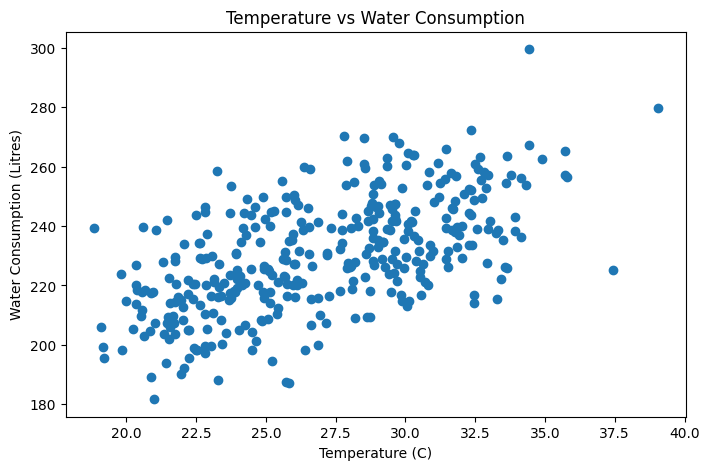

In [5]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['Temperature'],
    df['Water_Consumption']
)

plt.title("Temperature vs Water Consumption")
plt.xlabel("Temperature (C)")
plt.ylabel("Water Consumption (Litres)")

plt.show()

                   Temperature  Water_Consumption  Household_Size
Temperature           1.000000           0.594494       -0.005666
Water_Consumption     0.594494           1.000000       -0.032517
Household_Size       -0.005666          -0.032517        1.000000


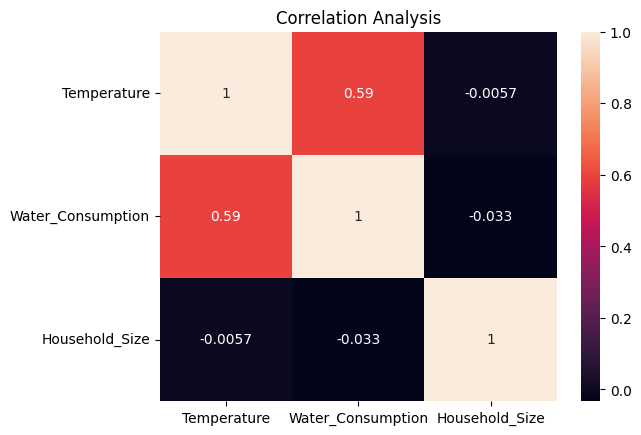

In [6]:
correlation = df[
    ['Temperature', 'Water_Consumption',
     'Household_Size']
].corr()

print(correlation)

sns.heatmap(correlation, annot=True)

plt.title("Correlation Analysis")

plt.show()

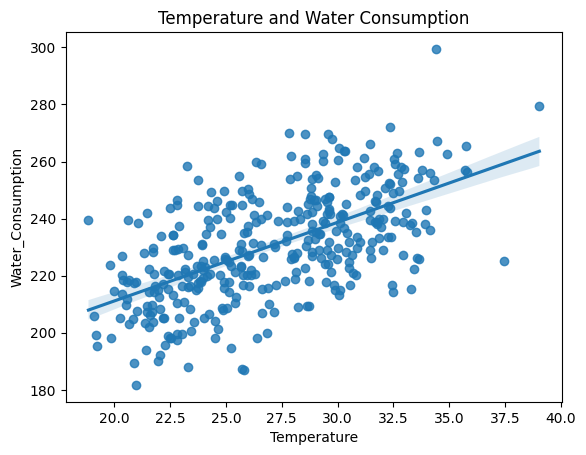

In [7]:
sns.regplot(
    x='Temperature',
    y='Water_Consumption',
    data=df
)

plt.title("Temperature and Water Consumption")

plt.show()

In [8]:
df['Date'] = pd.to_datetime(df['Date'])

df = df.set_index('Date')

print(df.head())

            Temperature  Water_Consumption  Season  Household_Size
Date                                                              
2025-01-01    23.663301         214.971597  Winter               4
2025-01-02    22.393344         220.541420  Winter               3
2025-01-03    23.965250         222.084636  Winter               6
2025-01-04    25.715933         228.612940  Winter               3
2025-01-05    22.201566         205.009552  Winter               5


In [9]:
monthly_data = df['Water_Consumption'].resample('ME').mean()

print(monthly_data)

Date
2025-01-31    219.038594
2025-02-28    225.098127
2025-03-31    228.176861
2025-04-30    237.515361
2025-05-31    241.822124
2025-06-30    242.274058
2025-07-31    244.369843
2025-08-31    240.455367
2025-09-30    232.999713
2025-10-31    221.350733
2025-11-30    219.614012
2025-12-31    213.393054
Freq: ME, Name: Water_Consumption, dtype: float64


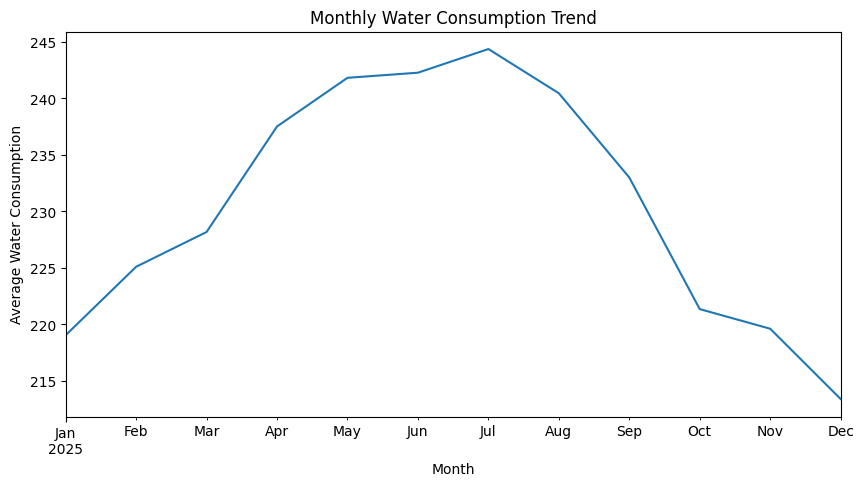

In [10]:
plt.figure(figsize=(10, 5))

monthly_data.plot()

plt.title("Monthly Water Consumption Trend")
plt.xlabel("Month")
plt.ylabel("Average Water Consumption")

plt.show()

Season
Monsoon    234.808501
Summer     237.406976
Winter     219.137908
Name: Water_Consumption, dtype: float64


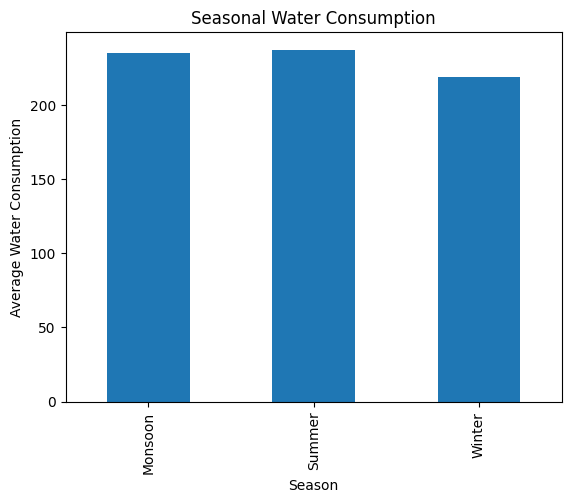

In [11]:
season_data = df.groupby('Season')['Water_Consumption'].mean()

print(season_data)

season_data.plot(kind='bar')

plt.title("Seasonal Water Consumption")
plt.xlabel("Season")
plt.ylabel("Average Water Consumption")

plt.show()

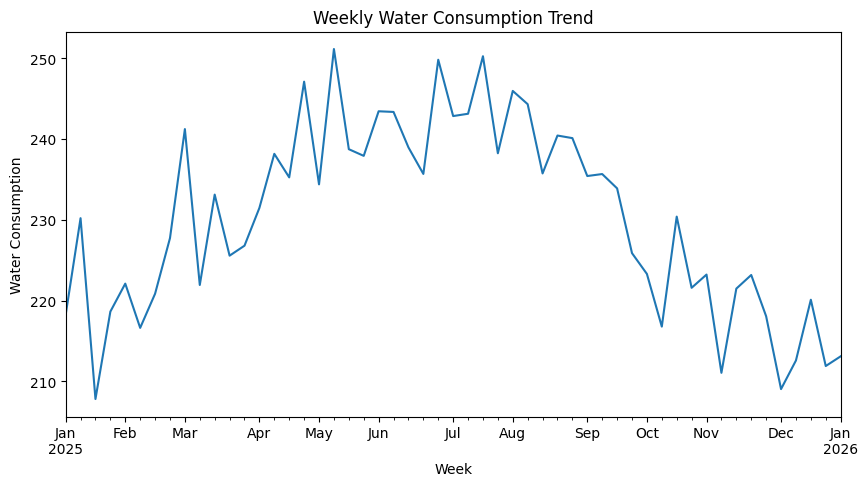

In [12]:
weekly_data = df['Water_Consumption'].resample('W').mean()

weekly_data.plot(figsize=(10, 5))

plt.title("Weekly Water Consumption Trend")
plt.xlabel("Week")
plt.ylabel("Water Consumption")

plt.show()

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
np.random.seed(42)

dates = pd.date_range(
    start='2025-01-01',
    periods=365,
    freq='D'
)

months = dates.month

temperature = (
    27 + 5 * np.sin(2 * np.pi * (months - 3) / 12)
    + np.random.normal(0, 2, 365)
)

consumption = (
    150 + temperature * 3
    + np.random.normal(0, 15, 365)
)

season = []

for month in months:
    if month in [3, 4, 5, 6]:
        season.append('Summer')
    elif month in [7, 8, 9, 10]:
        season.append('Monsoon')
    else:
        season.append('Winter')

data = {
    'Date': dates,
    'Temperature': temperature,
    'Water_Consumption': consumption,
    'Season': season,
    'Household_Size': np.random.randint(2, 7, 365)
}

df = pd.DataFrame(data)

print(df.head())

        Date  Temperature  Water_Consumption  Season  Household_Size
0 2025-01-01    23.663301         214.971597  Winter               4
1 2025-01-02    22.393344         220.541420  Winter               3
2 2025-01-03    23.965250         222.084636  Winter               6
3 2025-01-04    25.715933         228.612940  Winter               3
4 2025-01-05    22.201566         205.009552  Winter               5


In [15]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Description:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (365, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Date               365 non-null    datetime64[ns]
 1   Temperature        365 non-null    float64       
 2   Water_Consumption  365 non-null    float64       
 3   Season             365 non-null    object        
 4   Household_Size     365 non-null    int64         
dtypes: datetime64[ns](1), float64(2), int64(1), object(1)
memory usage: 14.4+ KB

Statistical Description:
                                Date  Temperature  Water_Consumption  \
count                            365   365.000000         365.000000   
mean   2025-07-01 23:59:59.999999744    27.031756         230.525057   
min              2025-01-01 00:00:00    18.843312         181.729400   
25%              2025-04-02 00:00:00    23.663301         217.501972 

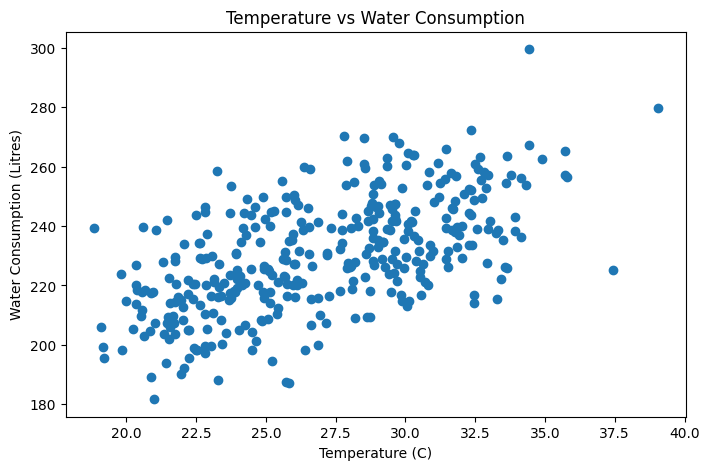

In [16]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['Temperature'],
    df['Water_Consumption']
)

plt.title("Temperature vs Water Consumption")
plt.xlabel("Temperature (C)")
plt.ylabel("Water Consumption (Litres)")

plt.savefig('scatter_plot.png')
plt.show()

                   Temperature  Water_Consumption  Household_Size
Temperature           1.000000           0.594494       -0.005666
Water_Consumption     0.594494           1.000000       -0.032517
Household_Size       -0.005666          -0.032517        1.000000


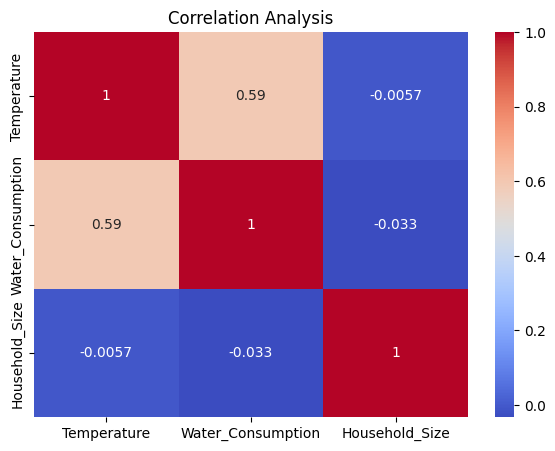

In [17]:
correlation = df[
    ['Temperature', 'Water_Consumption', 'Household_Size']
].corr()

print(correlation)

plt.figure(figsize=(7, 5))

sns.heatmap(correlation, annot=True, cmap='coolwarm')

plt.title("Correlation Analysis")

plt.savefig('correlation_heatmap.png')
plt.show()

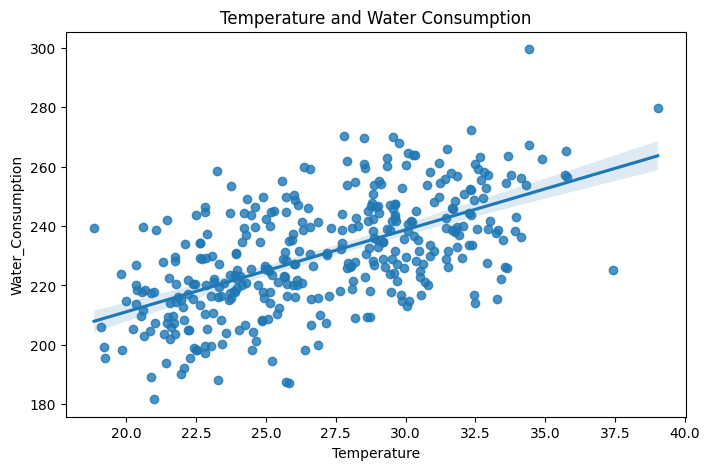

In [18]:
plt.figure(figsize=(8, 5))

sns.regplot(
    x='Temperature',
    y='Water_Consumption',
    data=df
)

plt.title("Temperature and Water Consumption")

plt.savefig('regression_plot.png')
plt.show()

In [19]:
df['Date'] = pd.to_datetime(df['Date'])

df = df.set_index('Date')

print(df.head())

            Temperature  Water_Consumption  Season  Household_Size
Date                                                              
2025-01-01    23.663301         214.971597  Winter               4
2025-01-02    22.393344         220.541420  Winter               3
2025-01-03    23.965250         222.084636  Winter               6
2025-01-04    25.715933         228.612940  Winter               3
2025-01-05    22.201566         205.009552  Winter               5


In [20]:
monthly_data = df['Water_Consumption'].resample('ME').mean()

print(monthly_data)

Date
2025-01-31    219.038594
2025-02-28    225.098127
2025-03-31    228.176861
2025-04-30    237.515361
2025-05-31    241.822124
2025-06-30    242.274058
2025-07-31    244.369843
2025-08-31    240.455367
2025-09-30    232.999713
2025-10-31    221.350733
2025-11-30    219.614012
2025-12-31    213.393054
Freq: ME, Name: Water_Consumption, dtype: float64


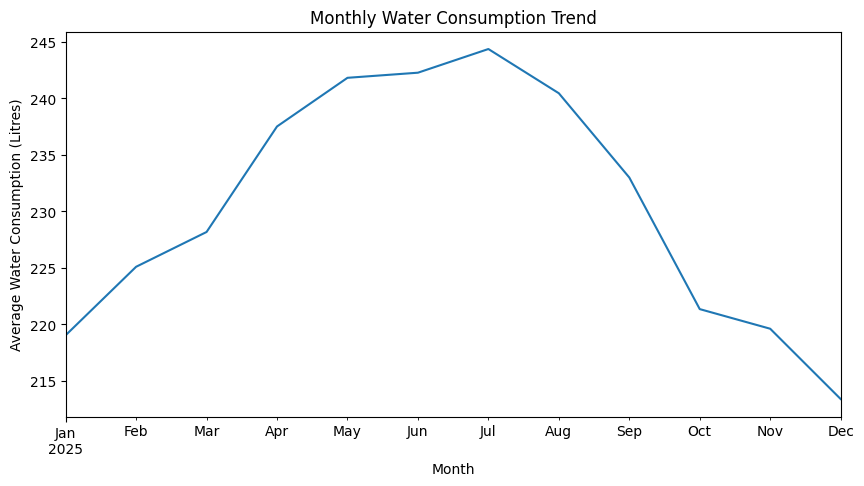

In [21]:
plt.figure(figsize=(10, 5))

monthly_data.plot()

plt.title("Monthly Water Consumption Trend")
plt.xlabel("Month")
plt.ylabel("Average Water Consumption (Litres)")

plt.savefig('monthly_trend.png')
plt.show()

Season
Monsoon    234.808501
Summer     237.406976
Winter     219.137908
Name: Water_Consumption, dtype: float64


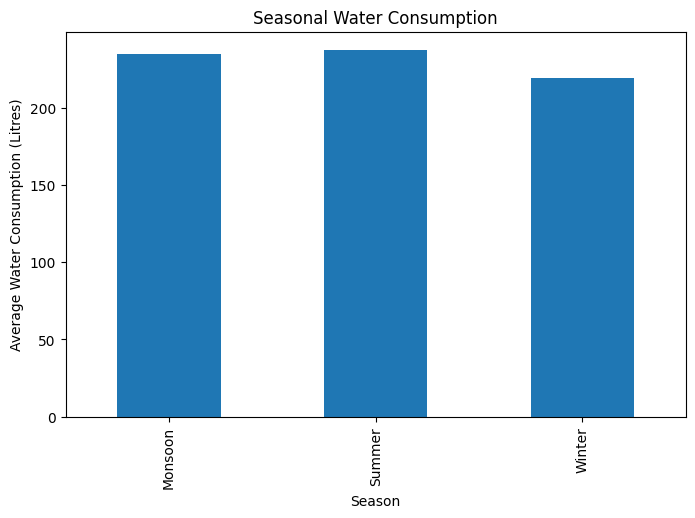

In [22]:
season_data = df.groupby('Season')['Water_Consumption'].mean()

print(season_data)

plt.figure(figsize=(8, 5))

season_data.plot(kind='bar')

plt.title("Seasonal Water Consumption")
plt.xlabel("Season")
plt.ylabel("Average Water Consumption (Litres)")

plt.savefig('seasonal_analysis.png')
plt.show()

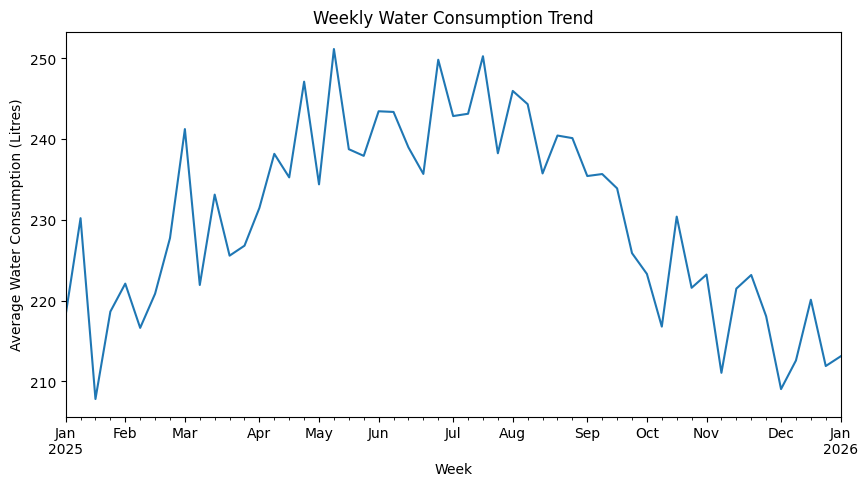

In [23]:
weekly_data = df['Water_Consumption'].resample('W').mean()

plt.figure(figsize=(10, 5))

weekly_data.plot()

plt.title("Weekly Water Consumption Trend")
plt.xlabel("Week")
plt.ylabel("Average Water Consumption (Litres)")

plt.savefig('weekly_trend.png')
plt.show()

In [24]:
df.to_csv('water_consumption.csv')

print("Dataset saved successfully!")

Dataset saved successfully!


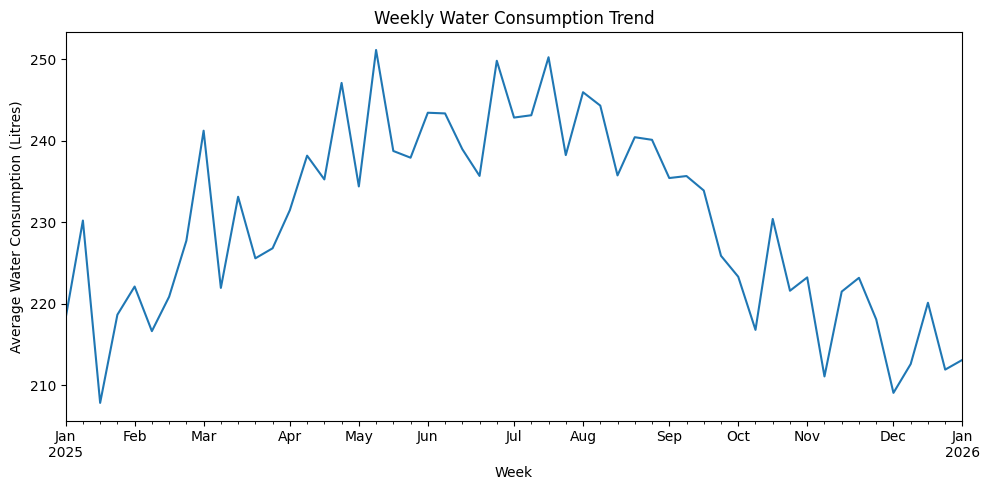

In [25]:
plt.figure(figsize=(10, 5))
weekly_data.plot()
plt.title("Weekly Water Consumption Trend")
plt.xlabel("Week")
plt.ylabel("Average Water Consumption (Litres)")
plt.tight_layout()
plt.savefig('weekly_trend.png')
plt.show()

In [26]:
from google.colab import files

files.download('water_consumption.csv')
files.download('scatter_plot.png')
files.download('correlation_heatmap.png')
files.download('regression_plot.png')
files.download('monthly_trend.png')
files.download('seasonal_analysis.png')
files.download('weekly_trend.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (4 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>